<a href="https://colab.research.google.com/github/guillebasterra/Audio-Visualizer/blob/master/02_milestone_experiments_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Milestone experiments: audio-only baseline under noise + PianoVAM rule filter
Runtime → Change runtime type → **GPU (T4)**. Requires `01_preprocess` to have written `data/PianoVAM/{Audio16k,Landmarks,TSV,metadata.json}` to Drive.

**What this produces (in `results/` on Drive):**
1. `video_coverage.csv` — for each ground-truth test note, is a fingertip over (±1/±2 white keys of) that key at onset? Sanity check of the keyboard mapping and a ceiling on what video can verify.
2. `noise_sweep_summary.csv`, `noise_sweep_per_recording.csv`, `noise_sweep.png` — pretrained audio-only transcriber (Kong et al., 2021) on the test split at clean / 20 / 10 / 5 / 0 / −5 dB white noise, with and without the PianoVAM-style rule-based video filter. Note-onset P/R/F1 via mir_eval (50 ms).

Tip: set `MAX_SEC = 120` first for a ~2-minute smoke test, then set it to `0` for the full run. Predictions are cached, so re-running is cheap.

**No Google Drive needed.** By default (`USE_DRIVE = False`) the next cell downloads the 9 test recordings straight from Hugging Face and preprocesses them exactly like `01_preprocess` (~10 min). Results go to `/content/results`; the last cell zips them for download.

In [ ]:
USE_DRIVE = False   # True = read preprocessed data from Google Drive (needs drive.mount to work)
!pip -q install piano_transcription_inference mir_eval
!nvidia-smi -L
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

GPU 0: Tesla T4 (UUID: GPU-6fe54e57-07ac-c866-f47e-fb7ef3462043)


In [ ]:
# Data: download + preprocess the 9 test recordings from Hugging Face (skipped if USE_DRIVE)
import os, json, shutil, numpy as np, librosa, soundfile as sf
if USE_DRIVE:
    ROOT = '/content/drive/MyDrive/DL-FinalProject/data/PianoVAM'
    OUT  = '/content/drive/MyDrive/DL-FinalProject/results'
else:
    from huggingface_hub import snapshot_download
    src, ROOT, OUT = '/content/PianoVAM', '/content/PianoVAM_test', '/content/results'
    snapshot_download('PianoVAM/PianoVAM_v1', repo_type='dataset', local_dir=src, allow_patterns=['metadata.json'])
    meta_raw = json.load(open(f'{src}/metadata.json'))
    test = sorted(v['record_time'] for v in meta_raw.values() if v['split'] == 'test')
    snapshot_download('PianoVAM/PianoVAM_v1', repo_type='dataset', local_dir=src,
                      allow_patterns=[f'{d}/{i}.{e}' for i in test for d, e in [('Audio','wav'), ('Handskeleton','json'), ('TSV','tsv')]])
    for d in ['Audio16k', 'Landmarks', 'TSV']:
        os.makedirs(f'{ROOT}/{d}', exist_ok=True)
    shutil.copy(f'{src}/metadata.json', ROOT)
    for i in test:
        if not os.path.exists(f'{ROOT}/Audio16k/{i}.wav'):
            y, _ = librosa.load(f'{src}/Audio/{i}.wav', sr=16000, mono=True)
            sf.write(f'{ROOT}/Audio16k/{i}.wav', y, 16000, subtype='PCM_16')
        if not os.path.exists(f'{ROOT}/Landmarks/{i}.npz'):
            d = json.load(open(f'{src}/Handskeleton/{i}.json')); T = max(int(k) for k in d) + 1
            X = np.full((T, 2, 21, 3), np.nan, dtype=np.float16)   # (frames, [Left, Right], 21 joints, xyz); NaN = no hand
            for t in range(T):
                f = d.get(str(t)) or {}
                for h, name in enumerate(['Left', 'Right']):
                    if f.get(name) is not None:
                        X[t, h] = f[name]
            np.savez_compressed(f'{ROOT}/Landmarks/{i}.npz', landmarks=X)
        shutil.copy(f'{src}/TSV/{i}.tsv', f'{ROOT}/TSV/')
        print('ready', i)
print('ROOT =', ROOT, '| OUT =', OUT)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 27 files:   0%|          | 0/27 [00:00<?, ?it/s]

ready 2024-02-14_19-55-17
ready 2024-02-14_20-10-08
ready 2024-02-15_20-17-26
ready 2024-02-15_20-47-59
ready 2024-02-17_21-44-37
ready 2024-09-02_14-10-41
ready 2024-09-02_21-04-45
ready 2024-09-03_00-07-46
ready 2024-09-03_00-44-45
ROOT = /content/PianoVAM_test | OUT = /content/results


In [ ]:
# Pretrained audio model checkpoint (Kong et al. 2021, Zenodo record 4034264, ~172 MB) -> path the package expects
import os, hashlib
CK = os.path.expanduser('~/piano_transcription_inference_data/note_F1=0.9677_pedal_F1=0.9186.pth')
os.makedirs(os.path.dirname(CK), exist_ok=True)
if not os.path.exists(CK) or os.path.getsize(CK) < 1.6e8:
    !wget -q -O "{CK}" "https://zenodo.org/records/4034264/files/CRNN_note_F1%3D0.9677_pedal_F1%3D0.9186.pth?download=1"
print(os.path.getsize(CK), hashlib.md5(open(CK,'rb').read()).hexdigest(), '(expected md5 22b961b77c1878239fec963362097045)')

# Newer PyTorch defaults torch.load(weights_only=True); this 2020 checkpoint is from the authors' official
# Zenodo record, so allow full unpickling for it.
import torch, functools
torch.load = functools.partial(torch.load, weights_only=False)

171966578 22b961b77c1878239fec963362097045 (expected md5 22b961b77c1878239fec963362097045)


In [ ]:
%%writefile /content/avpiano.py
"""Milestone pipeline: audio-only baseline under noise + PianoVAM-style rule-based video filter.

Data layout (produced by 01_preprocess.ipynb):
  ROOT/metadata.json, ROOT/Audio16k/<id>.wav, ROOT/Landmarks/<id>.npz, ROOT/TSV/<id>.tsv
"""
import os, json
import numpy as np
import soundfile as sf
import mir_eval

SR = 16000          # audio sample rate (Kong et al. model expects 16 kHz)
FPS_V = 60          # PianoVAM video / landmark frame rate
VID_W, VID_H = 1920, 1080   # PianoVAM video resolution (keyboard corners are in these pixels)
N_WHITE = 52        # white keys on an 88-key piano (A0..C8)
FINGERTIPS = [4, 8, 12, 16, 20]  # MediaPipe Hands fingertip landmark indices


# ---------------------------------------------------------------- data
def load_meta(root):
    meta = json.load(open(f'{root}/metadata.json'))
    return {v['record_time']: v for v in meta.values()}


def split_ids(meta, split):
    return sorted(i for i, v in meta.items() if v['split'] == split)


def load_audio(root, rid):
    y, sr = sf.read(f'{root}/Audio16k/{rid}.wav', dtype='float32')
    assert sr == SR, sr
    return y


def load_ref_notes(root, rid):
    """Ground-truth notes from PianoVAM TSV: columns onset, key_offset, frame_offset, note, velocity."""
    n = np.loadtxt(f'{root}/TSV/{rid}.tsv', skiprows=1, ndmin=2)
    onset, off = n[:, 0], n[:, 2]
    off = np.maximum(off, onset + 1e-2)          # mir_eval needs offset > onset
    return np.stack([onset, off], 1), n[:, 3].astype(int)


def crop_notes(intervals, pitches, max_sec):
    keep = intervals[:, 0] < max_sec
    return intervals[keep], pitches[keep]


# ---------------------------------------------------------------- audio degradation
def add_white_noise(y, snr_db, seed=0):
    """Additive white Gaussian noise at a given SNR (dB) w.r.t. the recording's mean power."""
    if snr_db is None:
        return y
    rng = np.random.default_rng(seed)
    p_sig = np.mean(y.astype(np.float64) ** 2)
    p_noise = p_sig / (10 ** (snr_db / 10))
    return (y + rng.normal(0, np.sqrt(p_noise), size=y.shape)).astype(np.float32)


# ---------------------------------------------------------------- audio-only transcription
def notes_from_events(events):
    if len(events) == 0:
        return np.zeros((0, 2)), np.zeros(0, int)
    iv = np.array([[e['onset_time'], max(e['offset_time'], e['onset_time'] + 1e-2)] for e in events])
    p = np.array([int(e['midi_note']) for e in events])
    ok = np.isfinite(iv).all(1)            # the regression post-processor can occasionally emit NaN times
    return iv[ok], p[ok]


def transcribe(transcriptor, y):
    out = transcriptor.transcribe(y, None)
    return notes_from_events(out['est_note_events'])


# ---------------------------------------------------------------- evaluation
def note_counts(ref_iv, ref_p, est_iv, est_p, onset_tol=0.05):
    """Onset-only note matching (mir_eval, 50 ms). Returns (n_matched, n_ref, n_est)."""
    if len(est_p) == 0 or len(ref_p) == 0:
        return 0, len(ref_p), len(est_p)
    m = mir_eval.transcription.match_notes(
        ref_iv, mir_eval.util.midi_to_hz(ref_p), est_iv, mir_eval.util.midi_to_hz(est_p),
        onset_tolerance=onset_tol, offset_ratio=None)
    return len(m), len(ref_p), len(est_p)


def prf(tp, n_ref, n_est):
    p = tp / n_est if n_est else 0.0
    r = tp / n_ref if n_ref else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f


# ---------------------------------------------------------------- hands -> keyboard coordinates
def homography(corners):
    """4 pixel corners (LT, RT, RB, LB) -> unit square (u: left->right along keyboard, v: top->bottom)."""
    dst = [(0, 0), (1, 0), (1, 1), (0, 1)]
    A = []
    for (x, y), (u, v) in zip(corners, dst):
        A += [[x, y, 1, 0, 0, 0, -u * x, -u * y, -u], [0, 0, 0, x, y, 1, -v * x, -v * y, -v]]
    _, _, Vt = np.linalg.svd(np.array(A, float))
    return Vt[-1].reshape(3, 3)


def keyboard_corners(m):
    return [tuple(map(float, m[k].split(','))) for k in ['Point_LT', 'Point_RT', 'Point_RB', 'Point_LB']]


def fingertips_on_keyboard(root, rid, m):
    """Returns (T, 10) array: fingertip position along the keyboard in white-key units (0..52); NaN if hand missing."""
    X = np.load(f'{root}/Landmarks/{rid}.npz')['landmarks'].astype(np.float32)   # (T, 2, 21, 3)
    tips = X[:, :, FINGERTIPS, :2].reshape(-1, 2) * [VID_W, VID_H]            # normalized -> pixels
    H = homography(keyboard_corners(m))
    p = np.c_[tips, np.ones(len(tips))] @ H.T
    u = (p[:, 0] / p[:, 2]).reshape(X.shape[0], 10)
    return u * N_WHITE


_WHITE_OFF = [0, None, 1, 2, None, 3, None, 4, 5, None, 6, None]   # A A# B C C# D D# E F F# G G#


def key_position(pitch):
    """Horizontal position of a MIDI pitch (21..108) in white-key units; black keys sit between whites."""
    octv, r = divmod(int(pitch) - 21, 12)
    if _WHITE_OFF[r] is not None:
        return octv * 7 + _WHITE_OFF[r] + 0.5
    return octv * 7 + _WHITE_OFF[r - 1] + 1.0


def nearest_tip_distance(tips_u, onsets, pitches, win=2):
    """Distance (white keys) from each note's key to the nearest fingertip within +-win frames of its onset.
    NaN when no hand is detected in that window."""
    T = tips_u.shape[0]
    kp = np.array([key_position(p) for p in pitches])
    d = np.full(len(onsets), np.nan)
    for j, (t, k) in enumerate(zip(onsets, kp)):
        f = int(round(t * FPS_V))
        w = tips_u[max(f - win, 0):min(f + win + 1, T)]
        if w.size and not np.all(np.isnan(w)):
            d[j] = np.nanmin(np.abs(w - k))
    return d


def rule_filter(est_iv, est_p, tips_u, tol=2.0, win=2):
    """PianoVAM-style post-processing: delete a predicted note if no fingertip is within `tol` white keys
    of its key at onset. Notes with no detected hand are kept (the rule cannot judge them)."""
    if len(est_p) == 0:
        return est_iv, est_p
    d = nearest_tip_distance(tips_u, est_iv[:, 0], est_p, win)
    keep = np.isnan(d) | (d <= tol)
    return est_iv[keep], est_p[keep]


Writing /content/avpiano.py


In [ ]:
import sys, os, time
sys.path.insert(0, '/content')
import numpy as np, pandas as pd
import avpiano as av

# ROOT and OUT are set by the data cell above
DEVICE  = 'cuda'
SPLIT   = 'test'
SNRS    = [None, 20, 10, 5, 0, -5]   # None = clean audio
MAX_SEC = 0     # smoke test: first 2 min of each recording. Set to 0 for the full run.
ONLY    = None    # or a single recording id, for debugging

MAX_SEC = MAX_SEC or None
os.makedirs(f'{OUT}/preds', exist_ok=True)
meta = av.load_meta(ROOT)
ids = [ONLY] if ONLY else av.split_ids(meta, SPLIT)
print(len(ids), 'recordings in', SPLIT, '| MAX_SEC =', MAX_SEC)

9 recordings in test | MAX_SEC = None


## 1) Video coverage of ground-truth notes (no model needed)

In [ ]:
rows = []
for rid in ids:
    tips = av.fingertips_on_keyboard(ROOT, rid, meta[rid])
    ref_iv, ref_p = av.load_ref_notes(ROOT, rid)
    if MAX_SEC: ref_iv, ref_p = av.crop_notes(ref_iv, ref_p, MAX_SEC)
    d = av.nearest_tip_distance(tips, ref_iv[:, 0], ref_p)
    rows.append(dict(id=rid, n_notes=len(ref_p), hand_seen=np.mean(~np.isnan(d)),
                     within_1=np.mean(d[~np.isnan(d)] <= 1), within_2=np.mean(d[~np.isnan(d)] <= 2),
                     median_dist=np.nanmedian(d)))
cov = pd.DataFrame(rows)
cov.to_csv(f'{OUT}/video_coverage.csv', index=False)
print(cov.round(3).to_string())
w = cov.n_notes / cov.n_notes.sum()
print('note-weighted: hand seen %.3f | fingertip within 2 keys %.3f | within 1 key %.3f'
      % ((w * cov.hand_seen).sum(), (w * cov.within_2).sum(), (w * cov.within_1).sum()))

                    id  n_notes  hand_seen  within_1  within_2  median_dist
0  2024-02-14_19-55-17     5629        1.0     0.996     0.999        0.115
1  2024-02-14_20-10-08     9357        1.0     0.995     0.997        0.132
2  2024-02-15_20-17-26     5045        1.0     0.950     0.951        0.148
3  2024-02-15_20-47-59     1662        1.0     0.986     0.986        0.116
4  2024-02-17_21-44-37      563        1.0     0.995     0.995        0.132
5  2024-09-02_14-10-41     1292        1.0     1.000     1.000        0.096
6  2024-09-02_21-04-45     2729        1.0     0.999     0.999        0.119
7  2024-09-03_00-07-46    10929        1.0     1.000     1.000        0.077
8  2024-09-03_00-44-45     5035        1.0     1.000     1.000        0.079
note-weighted: hand seen 1.000 | fingertip within 2 keys 0.993 | within 1 key 0.992


## 2) Audio-only transcription under noise, with and without the rule-based

1.   List item
2.   List item

video filter

In [ ]:
from piano_transcription_inference import PianoTranscription
transcriptor = PianoTranscription(device=DEVICE)

rows = []
for rid in ids:
    y = av.load_audio(ROOT, rid)
    if MAX_SEC: y = y[:int(MAX_SEC * av.SR)]
    ref_iv, ref_p = av.load_ref_notes(ROOT, rid)
    if MAX_SEC: ref_iv, ref_p = av.crop_notes(ref_iv, ref_p, MAX_SEC)
    tips = av.fingertips_on_keyboard(ROOT, rid, meta[rid])
    for k, snr in enumerate(SNRS):
        tag = 'clean' if snr is None else f'snr{snr}'
        cache = f'{OUT}/preds/{rid}_{tag}' + (f'_max{int(MAX_SEC)}' if MAX_SEC else '') + '.npz'
        if os.path.exists(cache):
            z = np.load(cache); est_iv, est_p = z['iv'], z['p']
        else:
            t0 = time.time()
            est_iv, est_p = av.transcribe(transcriptor, av.add_white_noise(y, snr, seed=k))
            np.savez(cache, iv=est_iv, p=est_p)
            print(f'{rid} {tag}: {len(est_p)} notes in {time.time()-t0:.0f}s')
        for method, (iv, p) in {'audio_only': (est_iv, est_p),
                                'audio+rule_filter': av.rule_filter(est_iv, est_p, tips)}.items():
            tp, nr, ne = av.note_counts(ref_iv, ref_p, iv, p)
            P, R, F = av.prf(tp, nr, ne)
            rows.append(dict(id=rid, snr=tag, method=method, tp=tp, n_ref=nr, n_est=ne, P=P, R=R, F1=F))

res = pd.DataFrame(rows)
res.to_csv(f'{OUT}/noise_sweep_per_recording.csv', index=False)

# micro-averaged over all test notes (sum TP / sum ref / sum est), plus mean of per-recording F1
order = ['clean'] + [f'snr{s}' for s in SNRS if s is not None]
g = res.groupby(['snr', 'method'])[['tp', 'n_ref', 'n_est']].sum().reset_index()
g[['P', 'R', 'F1']] = g.apply(lambda r: pd.Series(av.prf(r.tp, r.n_ref, r.n_est)), axis=1)
g['F1_mean_per_rec'] = res.groupby(['snr', 'method']).F1.mean().values
g['snr'] = pd.Categorical(g.snr, order); g = g.sort_values(['snr', 'method'])
g.to_csv(f'{OUT}/noise_sweep_summary.csv', index=False)
print((g.set_index(['snr', 'method'])[['P', 'R', 'F1', 'F1_mean_per_rec']] * 100).round(1).to_string())

Streaming output truncated to the last 5000 lines.
Segment 153 / 259
Segment 154 / 259
Segment 155 / 259
Segment 156 / 259
Segment 157 / 259
Segment 158 / 259
Segment 159 / 259
Segment 160 / 259
Segment 161 / 259
Segment 162 / 259
Segment 163 / 259
Segment 164 / 259
Segment 165 / 259
Segment 166 / 259
Segment 167 / 259
Segment 168 / 259
Segment 169 / 259
Segment 170 / 259
Segment 171 / 259
Segment 172 / 259
Segment 173 / 259
Segment 174 / 259
Segment 175 / 259
Segment 176 / 259
Segment 177 / 259
Segment 178 / 259
Segment 179 / 259
Segment 180 / 259
Segment 181 / 259
Segment 182 / 259
Segment 183 / 259
Segment 184 / 259
Segment 185 / 259
Segment 186 / 259
Segment 187 / 259
Segment 188 / 259
Segment 189 / 259
Segment 190 / 259
Segment 191 / 259
Segment 192 / 259
Segment 193 / 259
Segment 194 / 259
Segment 195 / 259
Segment 196 / 259
Segment 197 / 259
Segment 198 / 259
Segment 199 / 259
Segment 200 / 259
Segment 201 / 259
Segment 202 / 259
Segment 203 / 259
Segment 204 / 259
Segment 205 /

## 3) Figure

saved to /content/results


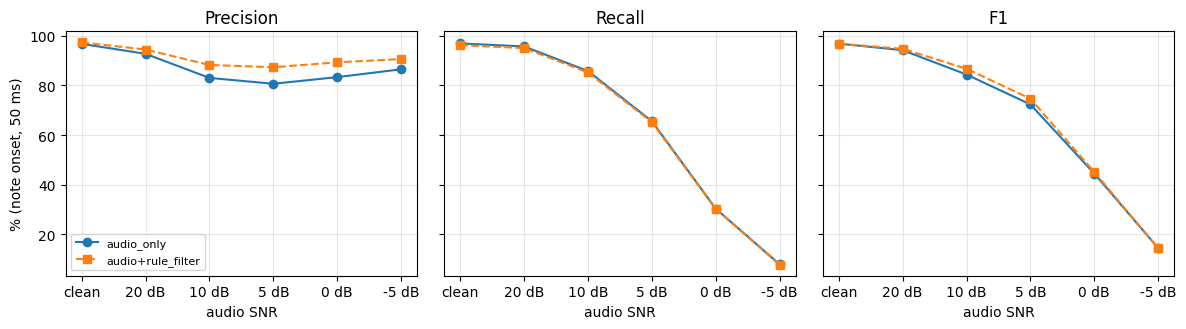

In [ ]:
import matplotlib; import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
x = np.arange(len(order)); labels = ['clean'] + [f'{s} dB' for s in SNRS if s is not None]
for ax, met in zip(axs, ['P', 'R', 'F1']):
    for method, mk in [('audio_only', 'o-'), ('audio+rule_filter', 's--')]:
        s = g[g.method == method].set_index('snr').reindex(order)
        ax.plot(x, 100 * s[met].values, mk, label=method)
    ax.set_xticks(x, labels); ax.set_title({'P': 'Precision', 'R': 'Recall', 'F1': 'F1'}[met])
    ax.set_xlabel('audio SNR'); ax.grid(alpha=.3)
axs[0].set_ylabel('% (note onset, 50 ms)'); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/noise_sweep.png', dpi=200)
print('saved to', OUT)

plt.show()

## 4) Download results (needed when not using Drive)

In [ ]:
!cd /content && zip -qr results.zip results -x 'results/preds/*'
from google.colab import files
files.download('/content/results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>